In [1]:
# Lasso & Ridge Regression (Regularization)
# Dataset: House Prices - Advanced Regression (Kaggle, same as multi-linear regression)
# ../Datasets/house_prices_train.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#df = pd.read_csv("../Datasets/house_prices_train.csv")

from sklearn.datasets import fetch_openml

In [2]:
housing = fetch_openml(name="house_prices", as_frame=True, parser="auto")
df = housing.frame

# ---- 1. Same setup as the multi-linear regression script ----
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
high_missing_cols = missing_pct[missing_pct > 40].index.tolist()
df = df.drop(columns=high_missing_cols)

# this time, use a WIDER set of numeric features on purpose - this is exactly
# the situation where Lasso/Ridge earn their keep over plain linear regression
# (more features -> more risk of overfitting / multicollinearity)
numeric_features = [
    "OverallQual", "OverallCond", "GrLivArea", "GarageCars", "GarageArea",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "FullBath", "HalfBath",
    "BedroomAbvGr", "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd",
    "Fireplaces", "LotArea", "LotFrontage", "MasVnrArea", "WoodDeckSF",
    "OpenPorchSF", "BsmtFinSF1"
]
numeric_features = [c for c in numeric_features if c in df.columns]

df_model = df[numeric_features + ["SalePrice"]].copy()

for col in numeric_features:
    df_model[col] = df_model[col].fillna(df_model[col].median())

df_model["SalePrice_log"] = np.log1p(df_model["SalePrice"])

X = df_model[numeric_features]
y = df_model["SalePrice_log"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---- 2. Scale - REQUIRED for Lasso/Ridge, since regularization penalizes
#          coefficient size, and that's meaningless if features aren't on the same scale ----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [3]:
# ---- 3. Baseline: plain Linear Regression ----
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)
print("Linear Regression R2:", r2_score(y_test, lr_pred))
print("Linear Regression coefficients (min/max):", lr.coef_.min(), lr.coef_.max())

# ---- 4. Ridge Regression (L2 penalty - shrinks coefficients, keeps all features) ----
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
ridge_pred = ridge.predict(X_test_scaled)
print("\nRidge R2:", r2_score(y_test, ridge_pred))
print("Ridge coefficients (min/max):", ridge.coef_.min(), ridge.coef_.max())

# ---- 5. Lasso Regression (L1 penalty - can shrink some coefficients to exactly 0) ----
lasso = Lasso(alpha=0.01)
lasso.fit(X_train_scaled, y_train)
lasso_pred = lasso.predict(X_test_scaled)
print("\nLasso R2:", r2_score(y_test, lasso_pred))

n_zeroed = (lasso.coef_ == 0).sum()
print(f"Lasso zeroed out {n_zeroed} of {len(numeric_features)} features")
# this is the key practical difference from Ridge - Lasso can do feature
# selection automatically by dropping features entirely


Linear Regression R2: 0.8723832538792099
Linear Regression coefficients (min/max): -0.02482815033668321 0.12055033158139473

Ridge R2: 0.872462413315612
Ridge coefficients (min/max): -0.01574533319025085 0.1204664893978103

Lasso R2: 0.8653876327413814
Lasso zeroed out 7 of 21 features


         Feature    Linear     Ridge     Lasso
0    OverallQual  0.120550  0.120466  0.121304
2      GrLivArea  0.097951  0.087064  0.086136
12     YearBuilt  0.083486  0.083049  0.071912
3     GarageCars  0.058829  0.058554  0.059101
1    OverallCond  0.052138  0.051950  0.036181
14    Fireplaces  0.039031  0.039002  0.034984
13  YearRemodAdd  0.028648  0.028839  0.029778
20    BsmtFinSF1  0.026690  0.026668  0.020615
7       2ndFlrSF -0.024828 -0.015745  0.000000
15       LotArea  0.023614  0.023577  0.016913
5    TotalBsmtSF  0.020648  0.020681  0.020217
11  TotRmsAbvGrd  0.019773  0.019917  0.013873
18    WoodDeckSF  0.015840  0.015854  0.012009
9       HalfBath  0.011617  0.011661  0.000000
4     GarageArea  0.010408  0.010698  0.006861
10  BedroomAbvGr  0.010076  0.010044  0.000000
17    MasVnrArea -0.005286 -0.005292  0.000000
16   LotFrontage -0.005235 -0.005201  0.000000
8       FullBath  0.003846  0.003914  0.000000
6       1stFlrSF -0.002742  0.005238  0.008314
19   OpenPorc

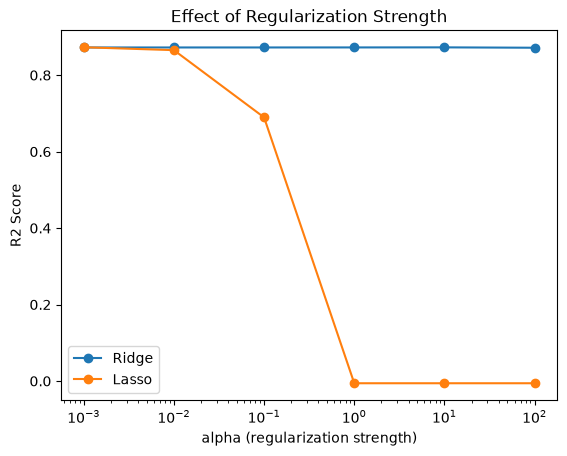

In [4]:
# ---- 6. Compare coefficients side by side ----
coef_compare = pd.DataFrame({
    "Feature": numeric_features,
    "Linear": lr.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_
})
print(coef_compare.sort_values("Linear", key=abs, ascending=False))

# ---- 7. Try a range of alpha values to see the effect of regularization strength ----
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
ridge_scores = []
lasso_scores = []

for a in alphas:
    r = Ridge(alpha=a).fit(X_train_scaled, y_train)
    l = Lasso(alpha=a, max_iter=5000).fit(X_train_scaled, y_train)
    ridge_scores.append(r2_score(y_test, r.predict(X_test_scaled)))
    lasso_scores.append(r2_score(y_test, l.predict(X_test_scaled)))

plt.plot(alphas, ridge_scores, marker="o", label="Ridge")
plt.plot(alphas, lasso_scores, marker="o", label="Lasso")
plt.xscale("log")
plt.xlabel("alpha (regularization strength)")
plt.ylabel("R2 Score")
plt.title("Effect of Regularization Strength")
plt.legend()
plt.show()


In [5]:
# too small an alpha barely regularizes at all (looks like plain linear regression)
# too large an alpha over-penalizes and underfits - there's a sweet spot in between

# ---- 8. Model comparison summary ----
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge", "Lasso"],
    "R2": [r2_score(y_test, lr_pred), r2_score(y_test, ridge_pred), r2_score(y_test, lasso_pred)],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred)),
    ]
})
print(results)

               Model        R2      RMSE
0  Linear Regression  0.872383  0.154320
1              Ridge  0.872462  0.154272
2              Lasso  0.865388  0.158493
